In [1]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay

In [2]:
import glob
import pandas as pd

data_path = glob.glob("/kaggle/input/**/*.csv", recursive=True)[0]
df = pd.read_csv(data_path)

print(df.shape)
df.head()

(569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass distribution:")
print(df["diagnosis"].value_counts())

Shape: (569, 32)

Columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Data types:
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_di

In [4]:
df = df.drop_duplicates().copy()
df = df.drop(columns=["id"])

numeric_features = df.select_dtypes(include=np.number).columns.drop("diagnosis", errors="ignore")
df[numeric_features] = df[numeric_features].apply(lambda x: x.fillna(x.median()))

df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})
df = df.dropna(subset=["diagnosis"])

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Missing values after preprocessing:", df.isnull().sum().sum())

Training set: (455, 30)
Testing set: (114, 30)
Missing values after preprocessing: 0


In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=5),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42)
}

results = []
predictions = {}
probabilities = {}
matrices = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, pred)

    predictions[name] = pred
    probabilities[name] = prob
    matrices[name] = cm

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.964912,0.975000,0.928571,0.951220,0.996032
1,Random Forest,0.973684,1.000000,0.928571,0.962963,0.994378
2,KNN,0.956140,0.974359,0.904762,0.938272,0.982308
3,Decision Tree,0.921053,0.945946,0.833333,0.886076,0.944775


In [6]:
for name, cm in matrices.items():
    print(name)
    print(cm)
    print()

Logistic Regression
[[71  1]
 [ 3 39]]

KNN
[[71  1]
 [ 4 38]]

Decision Tree
[[70  2]
 [ 7 35]]

Random Forest
[[72  0]
 [ 3 39]]



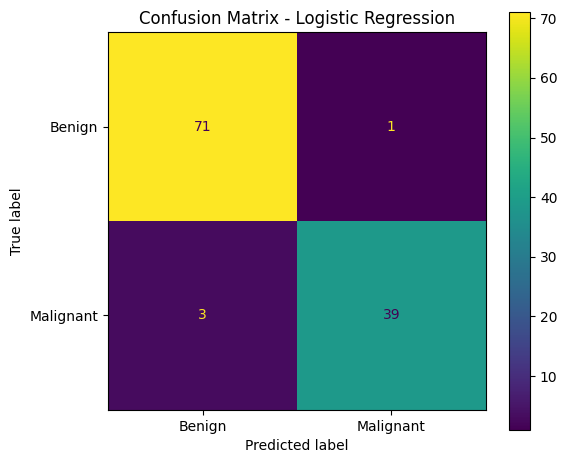

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
best_model_name = results_df.loc[0, "Model"]
ConfusionMatrixDisplay(
    confusion_matrix=matrices[best_model_name],
    display_labels=["Benign", "Malignant"]
).plot(ax=ax)
ax.set_title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

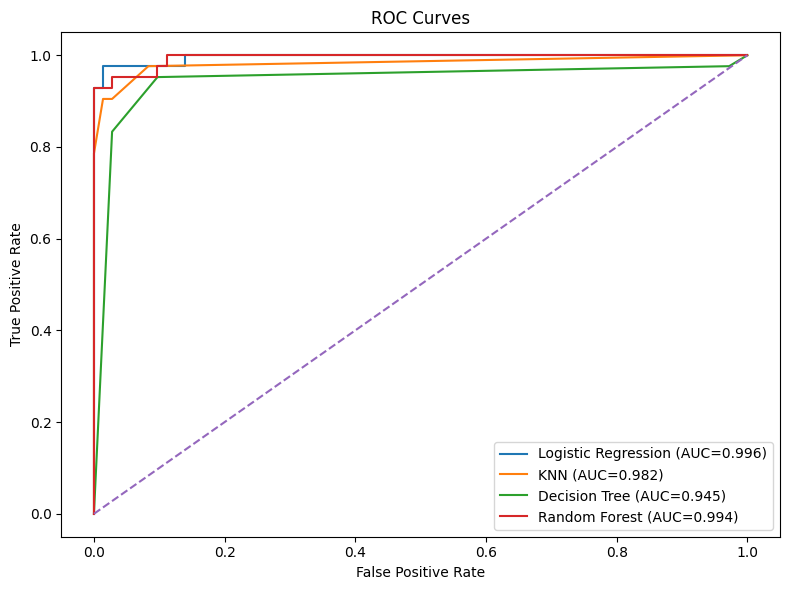

In [8]:
plt.figure(figsize=(8, 6))

for name in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc = roc_auc_score(y_test, probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

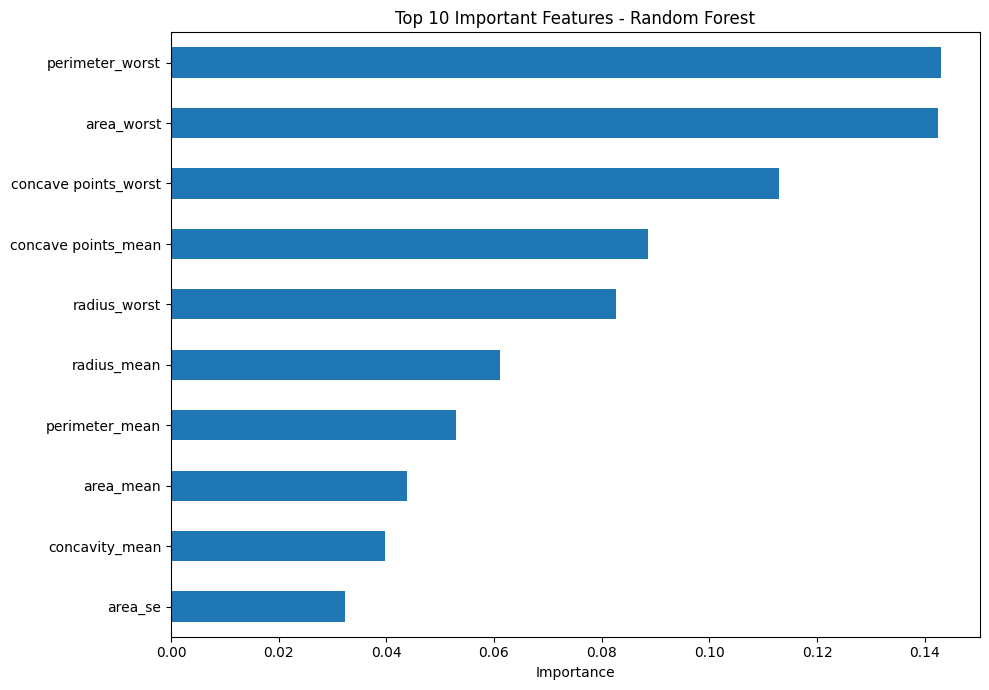

perimeter_worst         0.143121
area_worst              0.142449
concave points_worst    0.112978
concave points_mean     0.088663
radius_worst            0.082649
radius_mean             0.061043
perimeter_mean          0.052928
area_mean               0.043820
concavity_mean          0.039761
area_se                 0.032237
dtype: float64

In [9]:
rf = models["Random Forest"]
rf_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
rf_importance.head(10).sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()

rf_importance.head(10)

In [10]:
lr = models["Logistic Regression"].named_steps["model"]
lr_importance = pd.Series(
    np.abs(lr.coef_[0]),
    index=X.columns
).sort_values(ascending=False)

print(lr_importance.head(10))

texture_worst          1.434093
radius_se              1.233325
symmetry_worst         1.061264
concave points_mean    0.952813
concavity_worst        0.911406
area_se                0.909029
compactness_se         0.906925
area_worst             0.900477
radius_worst           0.896968
concavity_mean         0.782298
dtype: float64


In [11]:
best_model = results_df.loc[0, "Model"]
best_row = results_df.iloc[0]

print("Best model:", best_model)
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1-score:", round(best_row["F1-score"], 4))
print("ROC-AUC:", round(best_row["ROC-AUC"], 4))

Best model: Logistic Regression
Accuracy: 0.9649
Precision: 0.975
Recall: 0.9286
F1-score: 0.9512
ROC-AUC: 0.996


In [12]:
answers = {
    "Why is this a classification problem?": "The target has two categorical classes: benign and malignant.",
    "Why is feature scaling important for some models?": "Scaling puts numeric features on comparable ranges and is important for distance-based and coefficient-based models such as KNN and Logistic Regression.",
    "What is the difference between precision and recall?": "Precision measures how many predicted positive cases are actually positive, while recall measures how many actual positive cases are correctly detected.",
    "What does a false negative mean in this medical problem?": "A false negative means a malignant tumor is predicted as benign.",
    "Which model performs best and why?": f"{best_model} performs best according to the highest ROC-AUC on the test set.",
    "Is accuracy alone sufficient for evaluating this problem?": "No. Precision, recall, F1-score, confusion matrix, and ROC-AUC should also be considered, especially because false negatives are clinically important."
}

for question, answer in answers.items():
    print(question)
    print(answer)
    print()

Why is this a classification problem?
The target has two categorical classes: benign and malignant.

Why is feature scaling important for some models?
Scaling puts numeric features on comparable ranges and is important for distance-based and coefficient-based models such as KNN and Logistic Regression.

What is the difference between precision and recall?
Precision measures how many predicted positive cases are actually positive, while recall measures how many actual positive cases are correctly detected.

What does a false negative mean in this medical problem?
A false negative means a malignant tumor is predicted as benign.

Which model performs best and why?
Logistic Regression performs best according to the highest ROC-AUC on the test set.

Is accuracy alone sufficient for evaluating this problem?
No. Precision, recall, F1-score, confusion matrix, and ROC-AUC should also be considered, especially because false negatives are clinically important.



In [13]:
print("Conclusion")
print(f"The best-performing model on the test set is {best_model}.")
print("Model performance was evaluated using Accuracy, Precision, Recall, F1-score, Confusion Matrix, ROC Curve, and ROC-AUC.")
print("The most important features were analyzed using feature importance and logistic-regression coefficients.")

Conclusion
The best-performing model on the test set is Logistic Regression.
Model performance was evaluated using Accuracy, Precision, Recall, F1-score, Confusion Matrix, ROC Curve, and ROC-AUC.
The most important features were analyzed using feature importance and logistic-regression coefficients.
